# JS06 (ANN) - Praktikum 2: FAISS (Flat vs IVF + PQ)
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Pencarian kesamaan vektor menggunakan library FAISS buatan Facebook AI Research, membandingkan `IndexFlatL2` (exact brute force) dengan `IndexIVFPQ` (Inverted File + Product Quantization).


In [1]:
!pip install faiss-cpu


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 750 170]] distances: [[0.00013095 0.00079751 0.00077404]]
Waktu Exact Flat : 0.3209 ms
Waktu IVF+PQ     : 0.3166 ms


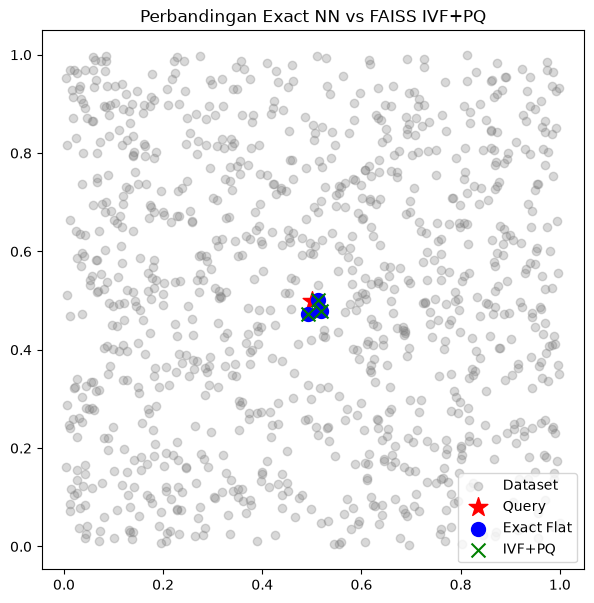

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Dataset 2D
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')
query = np.array([[0.5, 0.5]], dtype='float32')

# 2. Exact FlatL2
index_flat = faiss.IndexFlatL2(2)
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)
time_flat = time.time() - start

# 3. IVF + PQ
nlist = 10
m = 2
quantizer = faiss.IndexFlatL2(2)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)
index_ivfpq.train(X)
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
time_ivfpq = time.time() - start

print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print(f"Waktu Exact Flat : {time_flat*1000:.4f} ms")
print(f"Waktu IVF+PQ     : {time_ivfpq*1000:.4f} ms")

# Visualisasi
plt.figure(figsize=(7, 7))
plt.scatter(X[:,0], X[:,1], alpha=0.3, label="Dataset", color='gray')
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, label="Exact Flat")
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ")
plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()
